# 🧩 Autoencoders: Feature Extraction, Colorization and Enhancement

An autoencoder is a neural network that learns to compress an image and rebuild it. This notebook trains three of them from random weights on CIFAR-10, 60,000 small color photos in 10 classes, and uses them three ways:

| Task | Input → output | What it shows |
|---|---|---|
| **Feature extraction** | image → 128 numbers → class and similar images | The compressed numbers capture what the image shows |
| **Grayscale to color** | black-and-white image → color image | The network learns typical colors from context |
| **Image enhancement** | noisy, blurred image → clean image | The network learns to remove damage |

Each task is compared with a simple baseline, so the results show what the autoencoder adds. The images are only 32×32 pixels, so they look blurry when enlarged in the figures.

**To run:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Select `QUICK_CHECK` in Settings for a 2–3 minute test of every cell first.

In [1]:
#@title ⚙️ Settings
QUICK_CHECK = False      #@param {type:"boolean"}
# Select for a 2-3 minute run that checks every cell works. Its results will be poor.

EPOCHS = 15              #@param {type:"integer"}
# Passes over the training images for the enhancement model.
FEATURE_EPOCHS = 40      #@param {type:"integer"}
# Passes for the feature-extraction model, which takes about 4 seconds per pass on a T4.
COLOR_EPOCHS = 30        #@param {type:"integer"}
# Passes for the color model, whose training loss was still falling after 15.
LATENT_SIZE = 128        #@param {type:"integer"}
# How many numbers the first autoencoder squeezes each image into (an image has 3,072).
NOISE_LEVEL = 0.1        #@param {type:"number"}
# The strongest noise added for the enhancement task, with pixel values from 0 to 1.
SEED = 1337              #@param {type:"integer"}
SAVE_TO_DRIVE = True     #@param {type:"boolean"}

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WORK_DIR = "/content/autoencoder"
DRIVE_DIR = "/content/drive/MyDrive/autoencoder"

TRAIN_IMAGES = 2000 if QUICK_CHECK else 50000
if QUICK_CHECK:
    EPOCHS = 1
    FEATURE_EPOCHS = 1
    COLOR_EPOCHS = 1
print(f"{'Quick check' if QUICK_CHECK else 'Full run'}: {TRAIN_IMAGES} training images, {EPOCHS} epochs ({FEATURE_EPOCHS} for the feature model, {COLOR_EPOCHS} for the color model)")

Full run: 50000 training images, 15 epochs (40 for the feature model, 30 for the color model)


In [2]:
#@title 🔧 Setup: GPU, Google Drive, folders and helpers
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

if torch.cuda.is_available():
    DEVICE = "cuda"
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("No GPU found: training will be much slower. Choose Runtime > Change runtime type > T4 GPU.")
USE_AMP = DEVICE == "cuda"   # mixed precision is faster on a T4
torch.manual_seed(SEED)

WORK = Path(WORK_DIR)
WORK.mkdir(parents=True, exist_ok=True)

SAVE_DIR = None
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as error:
        # Drive is only a backup, so a refused mount (or running outside Colab) should not stop the run.
        print(f"Google Drive not mounted ({error}). Continuing: the models stay in {WORK_DIR} until this runtime ends.")
    else:
        SAVE_DIR = Path(DRIVE_DIR)
        SAVE_DIR.mkdir(parents=True, exist_ok=True)
        print("The trained models will also be copied to:", SAVE_DIR)


def show_rows(rows, row_titles, title=None, size=1.25, captions=None):
    # Draws rows of images (each a tensor of shape N x 3 x 32 x 32, values 0 to 1) one above the other.
    # captions, if given, holds one list of short texts per row, shown under each image.
    cols = max(len(r) for r in rows)
    fig, axes = plt.subplots(len(rows), cols, figsize=(cols * size + 1.8, len(rows) * (size + 0.25 * bool(captions))), squeeze=False)
    for r, (images, label) in enumerate(zip(rows, row_titles)):
        for c in range(cols):
            ax = axes[r][c]
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if c < len(images):
                ax.imshow(images[c].float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())
                if captions:
                    ax.set_xlabel(captions[r][c], fontsize=8)
        axes[r][0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=9)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def train(model, data, loss_on_batch, label, epochs=None):
    # A shared training loop: Adam, a learning rate that rises then falls (one cycle), and mixed precision on a GPU.
    # Each epoch goes through data in a random order; loss_on_batch(batch) returns the loss for one batch.
    epochs = epochs or EPOCHS
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    steps = epochs * math.ceil(len(data) / BATCH_SIZE)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, LEARNING_RATE, total_steps=steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = torch.zeros((), device=DEVICE)
        batches = torch.randperm(len(data), device=DEVICE).split(BATCH_SIZE)
        for idx in batches:
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
                loss = loss_on_batch(data[idx])
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            schedule.step()
            total += loss.detach()
        history.append(total.item() / len(batches))   # .item() also waits for the GPU to finish
        elapsed = time.time() - start
        print(f"{label} epoch {epoch}/{epochs}  loss {history[-1]:.4f}  "
              f"about {elapsed / epoch * (epochs - epoch) / 60:.1f} min left")
    print(f"{label}: trained in {(time.time() - start) / 60:.1f} minutes")
    model.eval()
    return history


@torch.no_grad()
def in_batches(fn, images, batch=500):
    # Runs fn over images (uint8) in batches without gradients, and joins the results.
    return torch.cat([fn(images[i:i + batch].float() / 255) for i in range(0, len(images), batch)])


def psnr(a, b):
    # Peak signal-to-noise ratio per image, in decibels: higher means closer to the original.
    mse = ((a.float() - b.float()) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return 10 * torch.log10(1 / mse)

GPU: Tesla T4
Mounted at /content/drive
The trained models will also be copied to: /content/drive/MyDrive/autoencoder


## 1. Data

[CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html), created by Alex Krizhevsky, Vinod Nair and Geoffrey Hinton and described in *Learning Multiple Layers of Features from Tiny Images* (Krizhevsky, 2009), has 50,000 training and 10,000 test images of 32×32 pixels, in 10 classes such as airplane, cat and truck. The images are small enough to keep on the GPU, which makes training faster. The test images are never used for training, so every result below is measured on images the models have not seen. The CIFAR-10 photos shown in this notebook remain the work of their original authors.

In [3]:
#@title 📚 Load CIFAR-10
import io

import pandas as pd
from huggingface_hub import hf_hub_download
from PIL import Image

# The Hugging Face copy of CIFAR-10 downloads much faster than the original server, and holds the same images.
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]


def load_split(name):
    # Returns the images as an N x 3 x 32 x 32 uint8 tensor (pixel values 0-255) and the labels.
    path = hf_hub_download("uoft-cs/cifar10", f"plain_text/{name}-00000-of-00001.parquet", repo_type="dataset",
                           cache_dir=str(WORK / "data"))
    table = pd.read_parquet(path)
    pixels = np.stack([np.array(Image.open(io.BytesIO(img["bytes"])).convert("RGB")) for img in table["img"]])
    return torch.from_numpy(pixels).permute(0, 3, 1, 2).contiguous(), torch.tensor(table["label"].to_numpy())


all_train_images, all_train_labels = load_split("train")
test_images, test_labels = load_split("test")
order = torch.randperm(len(all_train_images), generator=torch.Generator().manual_seed(SEED))[:TRAIN_IMAGES]
train_images, train_labels = all_train_images[order].to(DEVICE), all_train_labels[order]
test_images = test_images.to(DEVICE)
print(f"Training images: {len(train_images)} | test images: {len(test_images)}")
# The sample images shown in every task: the first test images of these classes, in this order.
SHOW_CLASSES = {"airplane": 1, "automobile": 1, "ship": 1, "truck": 1, "cat": 2, "dog": 2}
SHOW_IDX = [i for name, count in SHOW_CLASSES.items()
            for i in (test_labels == CLASS_NAMES.index(name)).nonzero().flatten()[:count].tolist()]
SHOW = test_images[SHOW_IDX].float() / 255

Training images: 50000 | test images: 10000


## 2. Feature extraction

The encoder turns the 3,072 numbers of each image (32×32 pixels × 3 colors) into 128 numbers that describe its content: its **features**. This section uses them to recognize the object in an image and to find images with similar content.

During training, a decoder tries to redraw each image from its 128 numbers, which forces them to hold the essentials of the image. The decoder never sees the original and does not know what it looks like: the 128 numbers are its only input. Its drawings keep only the broad colors and layout, so they serve training only and are not shown. A small classifier also predicts each training image's class from the same 128 numbers, so the features group images by what they show rather than by color alone. Each training image is randomly flipped and shifted, so the model learns the content rather than exact pixel positions.

The features are tested on the 10,000 test images:
- **Recognition:** how often the class predicted from the 128 numbers is right, for each class.
- **Linear classifier:** a new linear classifier trained on the features, compared with one trained on raw pixels and one on the features of an untrained encoder.
- **Map:** the features of 2,000 test images, flattened to two dimensions with t-SNE and colored by class.
- **Similar images:** how often the five images with the closest features share a test image's class, and four examples, the first automobile, ship, cat and dog in the test set, with the class of each match. Each example searches the test images labelled with the class the model recognizes in it, among airplanes, automobiles, ships, trucks, cats and dogs; the share above is measured over all 10,000 test images without this filter.

In [4]:
#@title 🧱 Build the autoencoder
# Type: a convolutional, undercomplete autoencoder with a label signal (a supervised autoencoder). Convolutional
# layers suit images, "undercomplete" means the middle (128 numbers) is much smaller than the input (3,072), and a
# small classifier on the middle numbers is trained alongside, so the features follow what the image shows.
class ConvAutoencoder(nn.Module):
    def __init__(self, latent):
        super().__init__()
        def down(cin, cout):   # halves the image size, then adds a second layer at the new size
            return nn.Sequential(nn.Conv2d(cin, cout, 3, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

        def up(cin, cout):     # doubles the image size
            return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

        self.encoder = nn.Sequential(down(3, 64), down(64, 128), down(128, 256),   # 32 -> 16 -> 8 -> 4
                                     nn.Flatten(), nn.Linear(256 * 4 * 4, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, 256 * 4 * 4), nn.Unflatten(1, (256, 4, 4)),
                                     up(256, 128), up(128, 64),                     # 4 -> 8 -> 16
                                     nn.ConvTranspose2d(64, 3, 4, stride=2, padding=1), nn.Sigmoid())   # -> 32
        self.classifier = nn.Linear(latent, 10)   # predicts the class from the 128 numbers

    def encode(self, x):
        return self.encoder(x)

    def forward(self, x):
        return self.decoder(self.encoder(x))


autoencoder = ConvAutoencoder(LATENT_SIZE).to(DEVICE)
print(f"Autoencoder parameters: {sum(p.numel() for p in autoencoder.parameters()) / 1e6:.1f} million")

Autoencoder parameters: 2.9 million


Autoencoder epoch 1/40  loss 0.2078  about 7.7 min left
Autoencoder epoch 2/40  loss 0.1540  about 4.8 min left
Autoencoder epoch 3/40  loss 0.1341  about 3.9 min left
Autoencoder epoch 4/40  loss 0.1212  about 3.4 min left
Autoencoder epoch 5/40  loss 0.1102  about 3.1 min left
Autoencoder epoch 6/40  loss 0.1006  about 2.8 min left
Autoencoder epoch 7/40  loss 0.0917  about 2.6 min left
Autoencoder epoch 8/40  loss 0.0868  about 2.5 min left
Autoencoder epoch 9/40  loss 0.0812  about 2.3 min left
Autoencoder epoch 10/40  loss 0.0773  about 2.2 min left
Autoencoder epoch 11/40  loss 0.0730  about 2.1 min left
Autoencoder epoch 12/40  loss 0.0692  about 2.0 min left
Autoencoder epoch 13/40  loss 0.0661  about 1.9 min left
Autoencoder epoch 14/40  loss 0.0624  about 1.8 min left
Autoencoder epoch 15/40  loss 0.0596  about 1.7 min left
Autoencoder epoch 16/40  loss 0.0564  about 1.6 min left
Autoencoder epoch 17/40  loss 0.0539  about 1.6 min left
Autoencoder epoch 18/40  loss 0.0518  ab

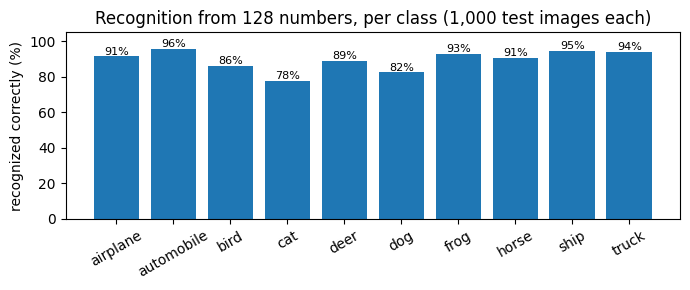

In [5]:
#@title 🚀 Train the autoencoder
CLASS_WEIGHT = 0.1   # how much the class prediction counts, relative to rebuilding the image
train_labels_gpu = train_labels.to(DEVICE)


def augment(x):
    # A random horizontal flip and a random shift of up to 4 pixels for each image.
    n = len(x)
    x = torch.where(torch.rand(n, 1, 1, 1, device=x.device) < 0.5, x.flip(3), x)
    padded = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i, j = torch.randint(0, 9, (2, n, 1), device=x.device)
    span = torch.arange(32, device=x.device)
    rows, cols = (i + span)[:, None, :, None], (j + span)[:, None, None, :]
    return padded[torch.arange(n, device=x.device)[:, None, None, None],
                  torch.arange(3, device=x.device)[None, :, None, None], rows, cols]


def ae_loss(idx):
    # train() passes positions in the training set, so each image and its label can be looked up together.
    x = augment(train_images[idx].float() / 255)
    z = autoencoder.encode(x)
    rebuild = F.mse_loss(autoencoder.decoder(z).float(), x)   # how far the rebuilt image is from the original
    classify = F.cross_entropy(autoencoder.classifier(z).float(), train_labels_gpu[idx])
    return rebuild + CLASS_WEIGHT * classify


ae_history = train(autoencoder, torch.arange(len(train_images), device=DEVICE), ae_loss, "Autoencoder", epochs=FEATURE_EPOCHS)

rebuilt = in_batches(autoencoder, test_images)
predicted = in_batches(lambda x: autoencoder.classifier(autoencoder.encode(x)), test_images).argmax(1).cpu()
correct = (predicted == test_labels).float()
print(f"\nClass recognized from the {LATENT_SIZE} numbers: {correct.mean():.1%} of the 10,000 test images")
print(f"The decoder's drawings, used only for training: PSNR {psnr(rebuilt, test_images.float() / 255).mean():.1f} dB")

# The features extracted from the sample images: the first 8 of their 128 numbers, and the class recognized from all 128.
with torch.no_grad():
    sample_features = autoencoder.encode(SHOW)
    sample_probabilities = F.softmax(autoencoder.classifier(sample_features), dim=1)
print(f"\nFeatures of the sample images (the first 8 of {LATENT_SIZE} numbers each):")
for idx, feature, probability in zip(SHOW_IDX, sample_features.cpu(), sample_probabilities.cpu()):
    numbers = " ".join(f"{value:6.2f}" for value in feature[:8].tolist())
    print(f"  {CLASS_NAMES[test_labels[idx]]:10} [{numbers} ...]  recognized: "
          f"{CLASS_NAMES[probability.argmax()]} ({probability.max():.0%})")

per_class = [correct[test_labels == c].mean().item() for c in range(len(CLASS_NAMES))]
plt.figure(figsize=(7, 3))
plt.bar(CLASS_NAMES, [100 * p for p in per_class])
for x, p in enumerate(per_class):
    plt.text(x, 100 * p + 1, f"{p:.0%}", ha="center", fontsize=8)
plt.ylim(0, 105)
plt.ylabel("recognized correctly (%)")
plt.xticks(rotation=30)
plt.title(f"Recognition from {LATENT_SIZE} numbers, per class (1,000 test images each)")
plt.tight_layout()
plt.show()

In [6]:
#@title 🔎 Are the features useful? A classifier on top
PROBE_TRAIN = min(10000, len(train_images))   # images used to train the small classifiers


def probe_accuracy(features_train, features_test):
    # A new linear classifier (logistic regression with mild L2 regularization), fitted on the GPU. It can only draw
    # straight boundaries, so it scores well only if the features already separate the classes.
    mean, std = features_train.mean(0), features_train.std(0).clamp_min(1e-6)
    a, b = (features_train - mean) / std, (features_test - mean) / std
    labels = train_labels[:PROBE_TRAIN].to(a.device)
    layer = nn.Linear(a.shape[1], 10).to(a.device)
    optimizer = torch.optim.LBFGS(layer.parameters(), max_iter=500, history_size=20, line_search_fn="strong_wolfe")

    def closure():
        optimizer.zero_grad()
        loss = F.cross_entropy(layer(a), labels) + 0.5 * layer.weight.pow(2).sum() / len(a)
        loss.backward()
        return loss

    optimizer.step(closure)
    with torch.no_grad():
        return (layer(b).argmax(1).cpu() == test_labels).float().mean().item()


untrained = ConvAutoencoder(LATENT_SIZE).to(DEVICE).eval()   # same design, random weights
probe_images = train_images[:PROBE_TRAIN]
pixels = lambda images: (images.float() / 255).flatten(1)
results = {
    "Raw pixels (3,072 numbers)": probe_accuracy(pixels(probe_images), pixels(test_images)),
    f"Untrained encoder ({LATENT_SIZE} numbers)": probe_accuracy(
        in_batches(untrained.encode, probe_images), in_batches(untrained.encode, test_images)),
    f"Trained encoder ({LATENT_SIZE} numbers)": probe_accuracy(
        in_batches(autoencoder.encode, probe_images), in_batches(autoencoder.encode, test_images)),
}
print(f"Accuracy on the 10,000 test images (10 classes, so chance is 10%), trained on {PROBE_TRAIN:,} images:")
for name, accuracy in results.items():
    print(f"  {name:32} {accuracy:.1%}")
print("The trained encoder learned from the labels, so this shows how much class information its features hold.")

Accuracy on the 10,000 test images (10 classes, so chance is 10%), trained on 10,000 images:
  Raw pixels (3,072 numbers)       28.1%
  Untrained encoder (128 numbers)  36.5%
  Trained encoder (128 numbers)    88.8%
The trained encoder learned from the labels, so this shows how much class information its features hold.


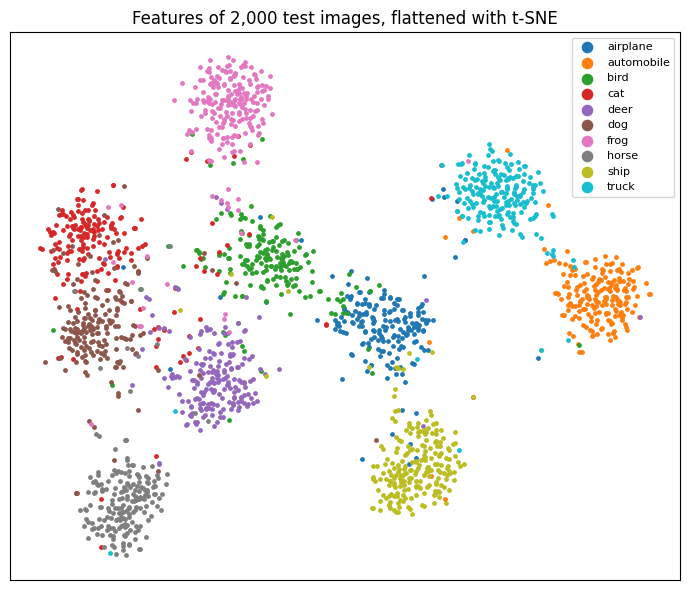

The 5 closest test images have the same class 85.9% of the time (10 classes, so chance is 10%)


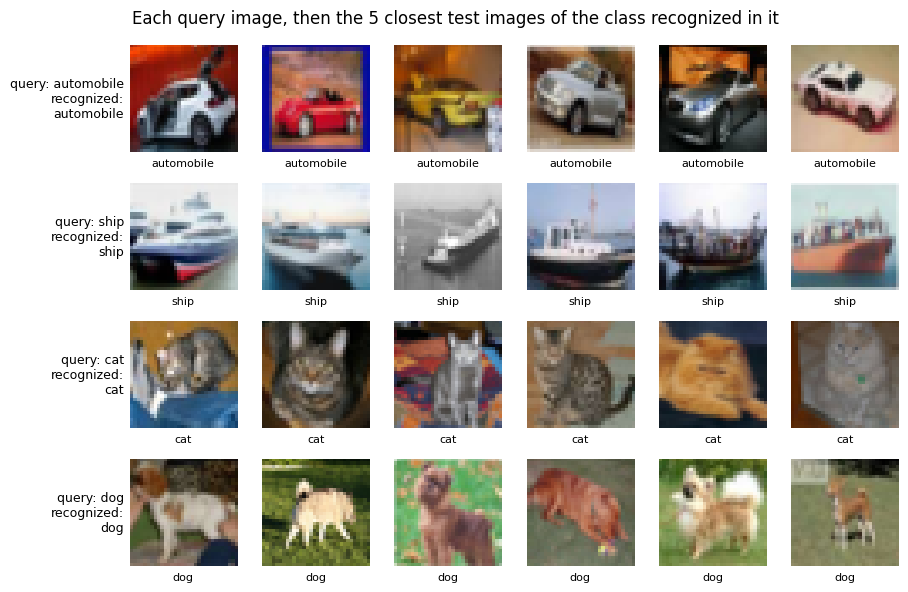

In [7]:
#@title 🗺️ Map the features and find similar images
from sklearn.manifold import TSNE

features = F.normalize(in_batches(autoencoder.encode, test_images), dim=1)
MAP_POINTS = 2000
points = TSNE(n_components=2, init="pca", random_state=SEED).fit_transform(features[:MAP_POINTS].cpu().numpy())
plt.figure(figsize=(7, 6))
for c, name in enumerate(CLASS_NAMES):
    mask = (test_labels[:MAP_POINTS] == c).numpy()
    plt.scatter(points[mask, 0], points[mask, 1], s=6, label=name)
plt.legend(markerscale=3, fontsize=8, loc="best")
plt.title(f"Features of {MAP_POINTS:,} test images, flattened with t-SNE")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()

# How often the 5 closest test images share the class of the image searched for, over all 10,000 test images.
same_class = 0
for s in range(0, len(features), 1000):
    similarity = features[s:s + 1000] @ features.T
    similarity[torch.arange(len(similarity)), torch.arange(s, s + len(similarity))] = -1   # leave out the image itself
    nearest = similarity.topk(5, dim=1).indices.cpu()
    same_class += (test_labels[nearest] == test_labels[s:s + 1000, None]).sum().item()
print(f"The 5 closest test images have the same class {same_class / (len(features) * 5):.1%} of the time "
      "(10 classes, so chance is 10%)")

# The first automobile, ship, cat and dog in the test set, each followed by the five others with the most similar features.
queries = [SHOW_IDX[1], SHOW_IDX[2], SHOW_IDX[4], SHOW_IDX[6]]
similarity = features[queries] @ features.T
similarity[torch.arange(len(queries)), torch.tensor(queries)] = -1   # leave out the image itself
# Each query searches the test images labelled with the class recognized in it, among the sample classes
# (airplane, automobile, ship, truck, cat, dog); a query recognized as another class searches all six.
sample_classes = torch.isin(test_labels, torch.tensor([CLASS_NAMES.index(name) for name in SHOW_CLASSES]))
for row, q in enumerate(queries):
    pool = sample_classes & (test_labels == predicted[q])
    if not pool.any():
        pool = sample_classes
    similarity[row, ~pool.to(similarity.device)] = -2
nearest = similarity.topk(5, dim=1).indices.cpu()
rows = [torch.cat([test_images[[q]], test_images[n]]).float() / 255 for q, n in zip(queries, nearest)]
captions = [[CLASS_NAMES[test_labels[i]] for i in [q, *n.tolist()]] for q, n in zip(queries, nearest)]
show_rows(rows, [f"query: {CLASS_NAMES[test_labels[q]]}\nrecognized:\n{CLASS_NAMES[predicted[q]]}" for q in queries],
          captions=captions, title="Each query image, then the 5 closest test images of the class recognized in it")

## 3. Grayscale to color

The color model works in the Lab color space, which separates brightness (L) from color (a and b). It receives only the brightness, which is the grayscale image, and predicts the two color channels. Combining its prediction with the original brightness gives the color image, so fine detail is always kept.

The network is a U-Net: an autoencoder with shortcuts between matching sizes, so detail can skip past the narrow middle.

Colorization has no single right answer: a car could be red or blue. A model trained to minimize its average error therefore tends toward safe, muted colors, which the notebook measures.

In [8]:
#@title 🧱 Build the U-Net (used for colorization and enhancement)
# Type: a U-Net, a convolutional encoder-decoder with skip connections. Strictly, it is not a classic autoencoder:
# for colorization its output differs from its input (brightness in, color out), and the skip connections let detail
# bypass the narrow middle. It keeps the encoder-decoder shape, so it is often grouped with autoencoders.
class UNet(nn.Module):
    def __init__(self, cin, cout, ch=48):
        super().__init__()
        def block(a, b):
            return nn.Sequential(nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU(),
                                 nn.Conv2d(b, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU())

        self.d1, self.d2, self.d3 = block(cin, ch), block(ch, ch * 2), block(ch * 2, ch * 4)   # 32, 16, 8
        self.mid = block(ch * 4, ch * 8)                                                     # 4
        self.up3, self.u3 = nn.ConvTranspose2d(ch * 8, ch * 4, 2, stride=2), block(ch * 8, ch * 4)
        self.up2, self.u2 = nn.ConvTranspose2d(ch * 4, ch * 2, 2, stride=2), block(ch * 4, ch * 2)
        self.up1, self.u1 = nn.ConvTranspose2d(ch * 2, ch, 2, stride=2), block(ch * 2, ch)
        self.out = nn.Conv2d(ch, cout, 1)

    def forward(self, x):
        h1 = self.d1(x)
        h2 = self.d2(F.max_pool2d(h1, 2))
        h3 = self.d3(F.max_pool2d(h2, 2))
        h = self.mid(F.max_pool2d(h3, 2))
        h = self.u3(torch.cat([self.up3(h), h3], dim=1))   # the shortcuts: join each size with its match
        h = self.u2(torch.cat([self.up2(h), h2], dim=1))
        h = self.u1(torch.cat([self.up1(h), h1], dim=1))
        return self.out(h)


print(f"U-Net parameters: {sum(p.numel() for p in UNet(3, 3).parameters()) / 1e6:.1f} million")

U-Net parameters: 4.3 million


Color model epoch 1/30  loss 0.0067  about 5.9 min left
Color model epoch 2/30  loss 0.0063  about 5.4 min left
Color model epoch 3/30  loss 0.0061  about 5.2 min left
Color model epoch 4/30  loss 0.0060  about 5.0 min left
Color model epoch 5/30  loss 0.0059  about 4.8 min left
Color model epoch 6/30  loss 0.0058  about 4.6 min left
Color model epoch 7/30  loss 0.0057  about 4.4 min left
Color model epoch 8/30  loss 0.0056  about 4.2 min left
Color model epoch 9/30  loss 0.0055  about 4.1 min left
Color model epoch 10/30  loss 0.0053  about 3.9 min left
Color model epoch 11/30  loss 0.0051  about 3.7 min left
Color model epoch 12/30  loss 0.0049  about 3.5 min left
Color model epoch 13/30  loss 0.0046  about 3.3 min left
Color model epoch 14/30  loss 0.0043  about 3.1 min left
Color model epoch 15/30  loss 0.0040  about 2.9 min left
Color model epoch 16/30  loss 0.0036  about 2.7 min left
Color model epoch 17/30  loss 0.0033  about 2.5 min left
Color model epoch 18/30  loss 0.0030  ab

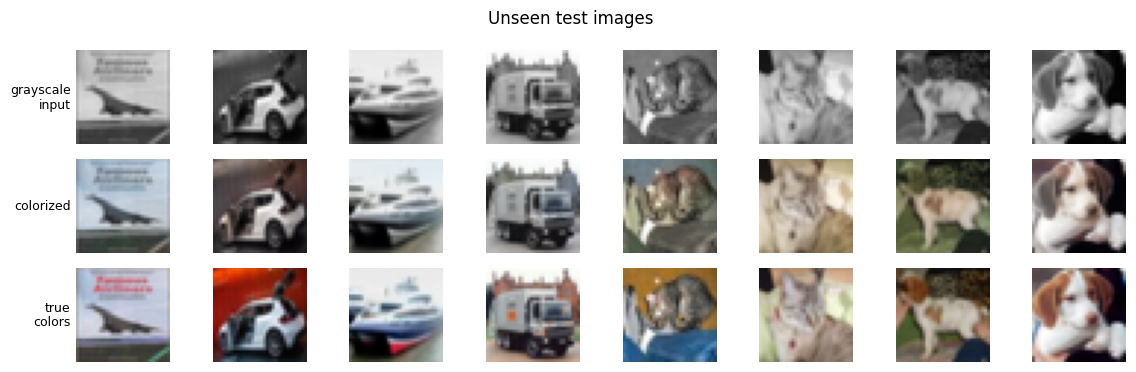

In [9]:
#@title 🎨 Train the color model
from skimage.color import lab2rgb, rgb2lab


def to_lab(images_uint8):
    # Brightness L becomes 0 to 1, and the color channels a and b roughly -1 to 1.
    lab = rgb2lab(images_uint8.permute(0, 2, 3, 1).cpu().numpy())
    lab = torch.from_numpy(lab).permute(0, 3, 1, 2).float()
    return torch.cat([lab[:, :1] / 100, lab[:, 1:] / 110], dim=1)


def to_rgb(L, ab):
    # Joins brightness and color, and converts back to RGB (values 0 to 1).
    lab = torch.cat([L * 100, ab * 110], dim=1).permute(0, 2, 3, 1).cpu().float().numpy()
    return torch.from_numpy(lab2rgb(lab)).permute(0, 3, 1, 2).float()


train_lab = torch.cat([to_lab(train_images[i:i + 5000]) for i in range(0, len(train_images), 5000)]).to(DEVICE)
test_lab = torch.cat([to_lab(test_images[i:i + 5000]) for i in range(0, len(test_images), 5000)]).to(DEVICE)
colorizer = UNet(1, 2).to(DEVICE)
nn.init.zeros_(colorizer.out.weight)   # starts by predicting no color, so training begins from the grayscale image
nn.init.zeros_(colorizer.out.bias)


def color_loss(lab):
    # The model sees only brightness (L) and predicts the two color channels (a, b).
    return F.smooth_l1_loss(torch.tanh(colorizer(lab[:, :1])).float(), lab[:, 1:])


color_history = train(colorizer, train_lab, color_loss, "Color model", epochs=COLOR_EPOCHS)


@torch.no_grad()
def colorize(lab):
    return torch.tanh(torch.cat([colorizer(lab[i:i + 500, :1]) for i in range(0, len(lab), 500)])).float()


predicted_ab = colorize(test_lab)
truth = test_images.float().cpu() / 255
colored = torch.cat([to_rgb(test_lab[i:i + 2000, :1], predicted_ab[i:i + 2000]) for i in range(0, len(test_lab), 2000)])
gray_rgb = torch.cat([to_rgb(test_lab[i:i + 2000, :1], torch.zeros_like(predicted_ab[i:i + 2000])) for i in range(0, len(test_lab), 2000)])
chroma = lambda ab: (ab * 110).pow(2).sum(1).sqrt().mean().item()   # average color strength
print(f"PSNR against the true colors, 10,000 test images: grayscale {psnr(gray_rgb, truth).mean():.1f} dB, "
      f"colorized {psnr(colored, truth).mean():.1f} dB")
print(f"Average color strength: true images {chroma(test_lab[:, 1:]):.1f}, colorized {chroma(predicted_ab):.1f} "
      "(lower means more muted)")
show_rows([gray_rgb[SHOW_IDX], colored[SHOW_IDX], truth[SHOW_IDX]], ["grayscale\ninput", "colorized", "true\ncolors"],
          title="Unseen test images")

## 4. Image enhancement

Each training image is damaged on the fly with a random amount of blur and noise, and a U-Net learns to repair it. It predicts a correction that is added to the damaged image, which is easier to learn than redrawing the whole image.

The results are measured with two standard scores, comparing the damaged and the repaired images with the originals:
- **PSNR** (peak signal-to-noise ratio): higher means closer to the original.
- **SSIM** (structural similarity, from 0 to 1): higher means the structure and edges match better.

Enhancement model epoch 1/15  loss 0.0039  about 4.2 min left
Enhancement model epoch 2/15  loss 0.0026  about 3.6 min left
Enhancement model epoch 3/15  loss 0.0024  about 3.2 min left
Enhancement model epoch 4/15  loss 0.0023  about 2.9 min left
Enhancement model epoch 5/15  loss 0.0022  about 2.6 min left
Enhancement model epoch 6/15  loss 0.0022  about 2.4 min left
Enhancement model epoch 7/15  loss 0.0022  about 2.1 min left
Enhancement model epoch 8/15  loss 0.0021  about 1.8 min left
Enhancement model epoch 9/15  loss 0.0021  about 1.6 min left
Enhancement model epoch 10/15  loss 0.0021  about 1.3 min left
Enhancement model epoch 11/15  loss 0.0021  about 1.0 min left
Enhancement model epoch 12/15  loss 0.0021  about 0.8 min left
Enhancement model epoch 13/15  loss 0.0020  about 0.5 min left
Enhancement model epoch 14/15  loss 0.0020  about 0.3 min left
Enhancement model epoch 15/15  loss 0.0020  about 0.0 min left
Enhancement model: trained in 3.9 minutes
            PSNR (dB) 

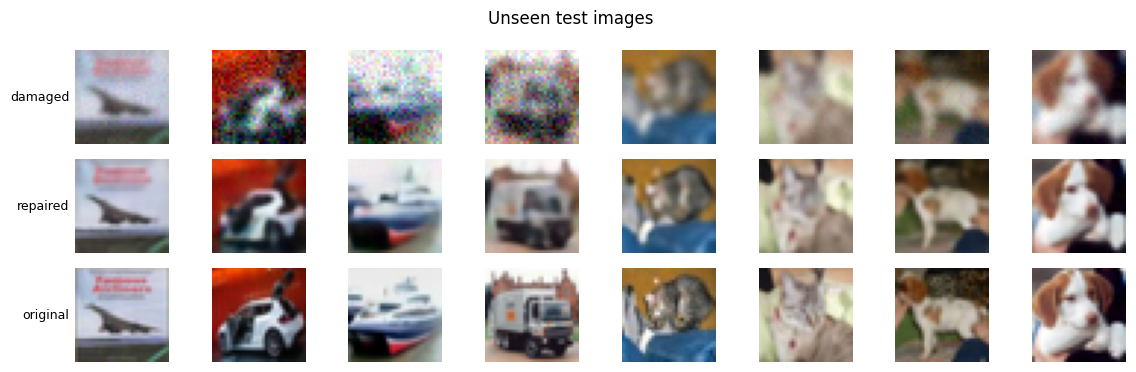

In [10]:
#@title ✨ Train the enhancement model
# Type: a denoising autoencoder, here also removing blur: it learns to rebuild the clean image from a damaged copy.
# It uses the U-Net above and predicts a correction that is added to the damaged image (a residual).
def degrade(x, generator=None):
    # Blurs each image by a random amount, then adds random noise. A generator makes the damage repeatable.
    n = len(x)
    rand = lambda: torch.rand(n, 1, 1, 1, device=x.device, generator=generator)
    sigma = 0.5 + rand().view(n) * 1.0                                    # blur strength 0.5 to 1.5 pixels
    offsets = torch.arange(-2, 3, device=x.device).float()
    kernel = torch.exp(-offsets[None] ** 2 / (2 * sigma[:, None] ** 2))
    kernel = (kernel / kernel.sum(1, keepdim=True)).repeat_interleave(3, dim=0)   # one kernel per color channel
    y = x.reshape(1, n * 3, 32, 32)
    y = F.conv2d(F.pad(y, (2, 2, 0, 0), mode="reflect"), kernel.view(n * 3, 1, 1, 5), groups=n * 3)   # across
    y = F.conv2d(F.pad(y, (0, 0, 2, 2), mode="reflect"), kernel.view(n * 3, 1, 5, 1), groups=n * 3)   # down
    y = y.view(n, 3, 32, 32)
    noise = torch.randn(y.shape, device=x.device, generator=generator)
    return (y + noise * rand() * NOISE_LEVEL).clamp(0, 1)


enhancer = UNet(3, 3).to(DEVICE)
nn.init.zeros_(enhancer.out.weight)   # starts by changing nothing, so training begins from the damaged image
nn.init.zeros_(enhancer.out.bias)


def enhance(x):
    return x + enhancer(x)   # the network predicts a correction for the damaged image


def enhance_loss(batch):
    x = batch.float() / 255
    return F.mse_loss(enhance(degrade(x)).float(), x)   # damage the image, repair it, compare with the original


enhance_history = train(enhancer, train_images, enhance_loss, "Enhancement model")

# The same damage every time for the test images, so results can be compared between runs.
clean = test_images.float() / 255
damaged = torch.cat([degrade(clean[i:i + 1000], torch.Generator(device=DEVICE).manual_seed(SEED + i))
                     for i in range(0, len(clean), 1000)])
with torch.no_grad():
    repaired = torch.cat([enhance(damaged[i:i + 500]).float().clamp(0, 1) for i in range(0, len(damaged), 500)])

from skimage.metrics import structural_similarity


def mean_ssim(a, b, count=1000):
    a, b = a[:count].permute(0, 2, 3, 1).cpu().numpy(), b[:count].permute(0, 2, 3, 1).cpu().numpy()
    return np.mean([structural_similarity(x, y, channel_axis=2, data_range=1.0) for x, y in zip(a, b)])


print(f"{'':10} {'PSNR (dB)':>10} {'SSIM':>7}")
print(f"{'damaged':10} {psnr(damaged, clean).mean():>10.1f} {mean_ssim(damaged, clean):>7.3f}")
print(f"{'repaired':10} {psnr(repaired, clean).mean():>10.1f} {mean_ssim(repaired, clean):>7.3f}")
print("PSNR is averaged over the 10,000 test images, SSIM over the first 1,000.")
show_rows([damaged[SHOW_IDX], repaired[SHOW_IDX], clean[SHOW_IDX]], ["damaged", "repaired", "original"], title="Unseen test images")

Models saved: /content/autoencoder/autoencoders.pt (44.1 MB)
Copied to: /content/drive/MyDrive/autoencoder/autoencoders.pt


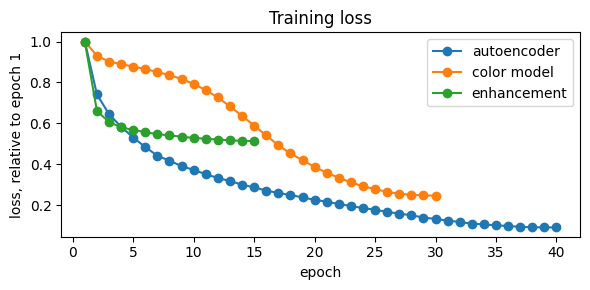

In [11]:
#@title 💾 Save the trained models
checkpoint = {"autoencoder": autoencoder.state_dict(), "colorizer": colorizer.state_dict(),
              "enhancer": enhancer.state_dict(), "latent_size": LATENT_SIZE, "noise_level": NOISE_LEVEL,
              "class_names": CLASS_NAMES}
MODEL_FILE = WORK / "autoencoders.pt"
torch.save(checkpoint, MODEL_FILE)
print(f"Models saved: {MODEL_FILE} ({MODEL_FILE.stat().st_size / 1024 / 1024:.1f} MB)")
if SAVE_DIR:
    torch.save(checkpoint, SAVE_DIR / MODEL_FILE.name)
    print("Copied to:", SAVE_DIR / MODEL_FILE.name)

plt.figure(figsize=(6, 3))
for history, label in ((ae_history, "autoencoder"), (color_history, "color model"), (enhance_history, "enhancement")):
    plt.plot(range(1, len(history) + 1), np.array(history) / history[0], marker="o", label=label)
plt.xlabel("epoch")
plt.ylabel("loss, relative to epoch 1")
plt.title("Training loss")
plt.legend()
plt.tight_layout()
plt.show()

## Tips

- **A first test:** select `QUICK_CHECK` in Settings. Every cell runs in a few minutes, but the results are poor.
- **Better results:** raise `EPOCHS`, for example to 30, which roughly doubles the training time.
- **Smaller or larger features:** change `LATENT_SIZE`. Fewer numbers compress more but rebuild less detail.
- **Harder enhancement:** raise `NOISE_LEVEL`, for example to 0.2.
- **Limits:** CIFAR-10 images are only 32×32 pixels, so results look small and soft. The same code works for larger images with more training time.